In [64]:
import torch
import torch.nn as nn
import torch.optim as optim       # weight update algorithm include
from torch.utils.data import TensorDataset, DataLoader
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [65]:
# Specially generate random weight like previous random_state
torch.manual_seed(42)

X, y = make_classification(n_samples=1000, n_features=3, n_informative=3,
                           n_redundant=0, random_state=42)  # Create Dataset

# n_informative -> No noice column

print(X)
print(X.shape)
print(y)
print(y.shape)

[[ 0.52170639  0.72685697  2.50410248]
 [-1.01971039 -0.74986039 -0.71346315]
 [-1.89222477 -1.03217141  1.54176061]
 ...
 [-2.00452836 -0.27580521 -2.15114866]
 [-1.27620641 -0.90958593  0.88747411]
 [ 0.89826016  0.97018038  1.39539407]]
(1000, 3)
[1 0 0 0 1 1 1 1 1 1 1 0 1 0 1 0 1 1 1 1 0 0 1 1 0 1 0 1 1 0 0 1 0 1 1 0 1
 0 0 1 0 1 0 0 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1 0 1 1 0 1 1 1 1 0 1 0 1 1 1
 1 0 1 1 1 1 1 1 1 1 0 0 0 0 1 1 0 0 1 1 0 1 0 0 1 1 1 0 1 1 0 0 1 0 0 0 1
 1 0 0 0 1 1 1 0 1 0 1 0 1 0 0 0 0 0 0 0 1 0 1 1 1 0 0 1 0 1 0 1 1 1 1 1 0
 0 1 1 0 0 1 0 0 1 1 1 1 1 0 1 0 1 1 0 1 0 1 1 1 1 0 0 1 1 0 0 1 0 0 0 1 1
 1 0 0 1 1 0 1 0 0 1 1 1 1 0 0 1 0 1 0 1 0 1 0 0 0 1 0 0 0 1 1 0 1 0 0 0 0
 0 1 0 1 1 0 0 1 1 0 1 0 0 1 1 0 1 1 0 1 0 1 0 0 1 1 0 1 1 1 0 1 0 0 0 1 0
 1 1 1 0 1 0 0 1 1 0 0 0 0 0 1 1 0 1 0 1 1 1 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1
 1 1 0 0 1 0 1 1 1 0 0 0 0 1 1 1 1 1 0 1 0 1 1 0 0 0 1 1 1 1 0 0 0 0 1 1 1
 0 0 0 0 1 0 1 1 1 0 1 0 1 1 1 1 1 0 1 1 1 1 0 0 0 1 1 0 1 1 0 0 1 0 0 1 1


In [66]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

In [67]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_val = scaler.transform(X_val)

X_test = scaler.transform(X_test)

Convert data to the
pytorch tensor format


In [68]:
X_train_t = torch.tensor(X_train, dtype=torch.float32)
# view mean 2 dimension ex: (3,) -> (3,1)
y_train_t = torch.tensor(y_train, dtype=torch.float32).view(-1, 1)

X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).view(-1, 1)

X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).view(-1, 1)

print(X_train_t)
print(X_train_t.shape)
print(type(X_train_t))

tensor([[ 1.4325, -1.5463,  1.2566],
        [ 0.4918, -0.2542, -0.6759],
        [ 0.7031,  0.2216, -0.3450],
        ...,
        [-1.2169, -0.2975, -0.9887],
        [ 0.4556, -1.1761,  0.4459],
        [ 0.3228, -2.3993,  1.5177]])
torch.Size([700, 3])
<class 'torch.Tensor'>


In [69]:
# split train X and y dataset glue together because we will separate batch wise dataset
train_dataset = TensorDataset(X_train_t, y_train_t)

# model train with batch wise dataset , 1 batch = 1 training step , each one batch have 32 dataset , shuffle means random order dataset for each epoch
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# batch size must be 16,32,64,128,256 (RAM Size)

print(train_loader)
print(type(train_loader))
print(list(train_loader))

<class 'torch.utils.data.dataloader.DataLoader'>
[[tensor([[-0.6529, -0.3078, -0.0881],
        [-0.0582, -0.6178,  0.9358],
        [ 1.0447,  1.8527,  0.3030],
        [ 0.3228, -2.3993,  1.5177],
        [-0.5869, -0.5249,  0.8395],
        [-1.1463, -0.1547, -0.1367],
        [-0.0375,  0.5932,  1.3446],
        [-0.9815, -0.3811,  0.6170],
        [ 1.4323, -1.5605,  1.3733],
        [ 1.1276,  2.0628, -0.0218],
        [ 1.0517,  0.2464, -0.1139],
        [-0.3723, -0.2930,  0.0640],
        [ 0.4439,  0.7297,  1.3407],
        [ 0.8541,  1.3852,  0.4131],
        [-0.4716, -1.2310, -2.2082],
        [ 0.3132, -0.5576,  0.0673],
        [-0.5260, -0.5716,  0.8359],
        [ 0.4061,  0.5597,  0.9310],
        [ 0.4501, -1.6950,  0.6607],
        [ 0.1195,  0.5108,  0.8562],
        [ 0.0522, -0.2517,  0.1088],
        [-0.1911, -0.2036, -0.2540],
        [-0.1077, -0.6601,  0.8978],
        [ 0.9800,  1.2117,  0.4579],
        [-0.2013, -0.9562, -0.4364],
        [-1.8523,  1.075

Design Neural Network Architecture


In [70]:
class CustomerPredictor(nn.Module):

    def __init__(self):
        super().__init__()
        self.hidden = nn.Linear(3, 8)
        self.output = nn.Linear(8, 1)

    def forward(self, x):
        x = torch.relu(self.hidden(x))
        return self.output(x)


model = CustomerPredictor()

In [71]:
print(list(model.parameters()))

[Parameter containing:
tensor([[-0.1265,  0.1165, -0.2811],
        [ 0.3391,  0.5090, -0.4236],
        [ 0.5018,  0.1081,  0.4266],
        [ 0.0782,  0.2784, -0.0815],
        [ 0.4451,  0.0853, -0.2695],
        [ 0.1472, -0.2660, -0.0677],
        [-0.2345,  0.3830, -0.4557],
        [-0.2662, -0.1630, -0.3471]], requires_grad=True), Parameter containing:
tensor([ 0.0545, -0.5702,  0.5214, -0.4904,  0.4457,  0.0961, -0.1875,  0.3568],
       requires_grad=True), Parameter containing:
tensor([[ 0.0551,  0.2857,  0.0387, -0.1115,  0.0950, -0.0959,  0.1488,  0.3157]],
       requires_grad=True), Parameter containing:
tensor([0.2044], requires_grad=True)]


In [72]:
# currently give score only so calculate probability and loss error using this function
loss_function = nn.BCEWithLogitsLoss()

# AdamW means update weights and bias algorithm , lr (Learning rate) , lr and weight_decay are hyperparameters
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

In [73]:
epochs = 50  # hyperparameter , number of training iteration
train_losses = []  # store train loss for each epoch
val_losses = []  # store validation loss for each epoch
# store best model for each epoch (Store best weights and bias and architecture in this file )
CHECKPOINT_PATH = "best_customer_predictor.pt"
# Store best validation loss for each epoch , initially set to infinity
best_val_loss = float('inf')

print("Starting Training...")

for epoch in range(epochs):

    model.train()  # this important for dropout and batch normalization layer , if you don't use this then dropout and batch normalization layer will not work properly
    epoch_train_loss = 0.0

    for batch_X, batch_y in train_loader:

        optimizer.zero_grad()  # Previous batch gradients will be cleared

        # score for each batch dataset , logits is the output of the model before applying sigmoid function , one batch return 32 scores because batch size is 32 , forward pass
        logits = model(batch_X)

        # give a average of loss for each batch dataset , sigmoid function is applied inside the loss function , so we don't need to apply sigmoid function here
        loss = loss_function(logits, batch_y)

        loss.backward()  # calculate gradients

        optimizer.step()  # update weights and bias

        epoch_train_loss += loss.item()  # store loss for each batch

    # average loss for each epoch (Per sample loss)
    avg_train_loss = epoch_train_loss / len(train_loader)
    train_losses.append(avg_train_loss)

# Calculate validation loss (If we have large validation dataset then we can use batch wise validation dataset like training dataset , but here we have small validation dataset so we can use all validation dataset at once)

    model.eval()  # this important for dropout and batch normalization layer , if you don't use this then dropout and batch normalization layer will not work properly

    with torch.no_grad():  # we are not use backpropagation this part so we don't need to calculate gradients , this will save memory and speed up the training process , only doing forward propagation.
        # Forward propagation for validation dataset
        val_logits = model(X_val_t)
        val_loss = loss_function(val_logits, y_val_t)
    val_losses.append(val_loss.item())

    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()  # Store the best validation loss
        # Save the model state dictionary (weights and biases)
        torch.save(model.state_dict(), CHECKPOINT_PATH)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {val_loss.item():.4f}")

Starting Training...


Epoch 10/50 | Train Loss: 0.5098 | Val Loss: 0.4771
Epoch 20/50 | Train Loss: 0.3288 | Val Loss: 0.2715
Epoch 30/50 | Train Loss: 0.2534 | Val Loss: 0.1820
Epoch 40/50 | Train Loss: 0.2271 | Val Loss: 0.1486
Epoch 50/50 | Train Loss: 0.2154 | Val Loss: 0.1360


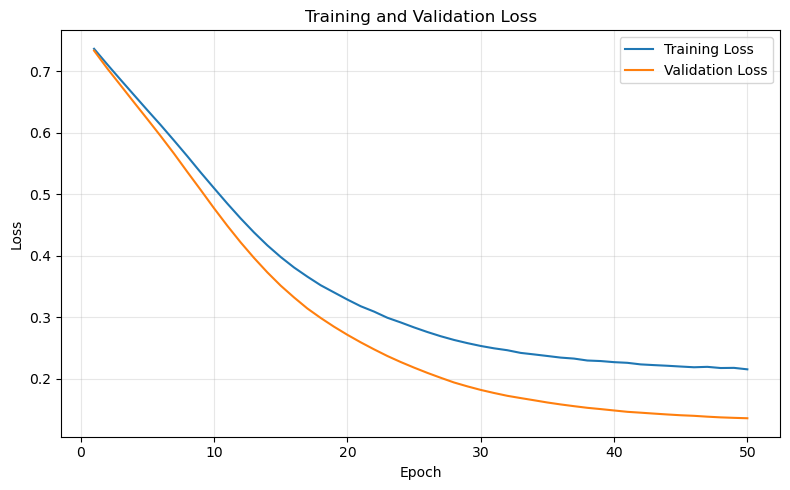

In [74]:
# Plot training and validation loss for each epoch
epoch_numbers = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epoch_numbers, train_losses, label="Training Loss")
plt.plot(epoch_numbers, val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [75]:
try:
    ckpt = torch.load(CHECKPOINT_PATH, map_location="cpu", weights_only=True)

except TypeError:
    ckpt = torch.load(CHECKPOINT_PATH, map_location="cpu")

# when we run another location run this project we need to create model = CustomerPredictor() before load_state_dict because model architecture is not saved in the checkpoint file, only weights and biases are saved. So we need to create the model architecture first before loading the weights and biases.
model.load_state_dict(ckpt)
print(
    f"Training Complete! Loaded best checkpoint (val loss {best_val_loss:.4f})")

Training Complete! Loaded best checkpoint (val loss 0.1360)


In [81]:
model.eval()

with torch.no_grad():
    test_logits = model(X_test_t)

    # Apply sigmoid to get probabilities
    test_proba = torch.sigmoid(test_logits).numpy().ravel()

    y_true = y_test_t.numpy().ravel() # Convert tensors into numpy array and flatten to 1D array because we can't get classification report from 2D array, we need to flatten it to 1D array. 

    # Convert probabilities to binary predictions
    y_pred = (test_proba >= 0.5).astype(int)

print(f"y pred: {y_pred}")

print("Classification Report")
print(classification_report(y_true, y_pred))

print("Confusion Matrix")
print(confusion_matrix(y_true, y_pred))



y pred: [0 1 0 1 1 1 1 1 0 1 0 1 0 1 1 0 1 0 0 1 1 0 1 1 0 0 1 0 0 0 0 1 0 1 1 0 0
 1 0 1 1 0 1 1 0 0 0 1 1 0 0 0 1 1 1 0 1 0 0 0 0 0 0 0 0 0 1 0 1 0 0 0 1 1
 0 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 0 1 1 0 1 1 0 1 1 0 1 0 1 0 0 1 0 1 0 1 0
 0 0 1 1 0 0 0 1 1 1 0 1 1 0 1 1 0 0 0 1 0 0 0 1 1 0 0 1 0 1 0 1 0 1 0 0 0
 1 1]
Classification Report
              precision    recall  f1-score   support

         0.0       0.88      0.96      0.92        75
         1.0       0.96      0.87      0.91        75

    accuracy                           0.91       150
   macro avg       0.92      0.91      0.91       150
weighted avg       0.92      0.91      0.91       150

Confusion Matrix
[[72  3]
 [10 65]]


In [77]:
print(torch.__version__)

2.14.1+cpu


Inference

In [85]:
new_customer =[[1.0, 2.0, 3.0]]

new_customer_t = torch.tensor(scaler.transform(new_customer), dtype=torch.float32)

model.eval()
with torch.no_grad():
    prediction_logits = model(new_customer_t)
    p_buy = torch.sigmoid(prediction_logits).item()
    print(f"predicted probability : {p_buy:.4f}")


if p_buy >= 0.5:
    print("Customer will buy the product")
else:
    print("Customer will not buy the product")





predicted probability : 0.9966
Customer will buy the product
